# HanuAi ML Assessment — Task 2: EDA and Text Mining

**Purpose:** audit the provided event dataset, clean date/text fields, extract interpretable entity tags, classify issue types, and explore complaint text using TF-IDF + K-Means.

**Important limitations:** keyword tags and issue categories are heuristic labels, not ground truth. Clusters are exploratory groups, not confirmed root causes. The dataset appears to contain automotive infotainment/electrical event narratives; validate domain assumptions with the data owner.

Run from a folder containing `Hanuai task2 assignment.csv`, or update `DATA_PATH` below.

In [1]:
# Imports: install dependencies if needed with: pip install pandas numpy matplotlib seaborn scikit-learn
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore")
sns.set_theme()
DATA_PATH = "Hanuai task2 assignment.csv"  # change to your file path if needed
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (1000, 20)


,Event id,Opened date,CAUSAL_VERBATIM,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,BUILD_DATE,BUILD_PLANT_DESC,CAUSAL_CD_DESC,COMPLAINT_CD_DESC,IN_USE_DATE,MAKE,MODEL,MODLYR,PLANT,Trigger,Failure Component,Failure Condition,Additional Context,Fix Component,Fix Condition
0,D-14801,9/17/2019,unable to duplicate the concern at this time r...,"waiting for techline engineering response, att...",Customer reports that radio and screen is inte...,2019-08-14T00:00:00.000Z,Flint,Module/Component-No/Incorrect Communication,Audio/Entertainment/Navigation - Other issues,2019-09-10T00:00:00.000Z,NovaSprint,AeroSpecter,2020,FLT,['No Additional Functionality'],"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']",['No Additional Context'],"['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,7/6/2020,upon inspection radio screen was found to be b...,and ground at radio as stated in service info ...,RADIO IS INOPERABLE CHECK AND ADVISE,2019-08-16T00:00:00.000Z,Fort Wayne,Module/Component-Shorted,Audio/Entertainment/Navigation - Other issues,2020-03-26T00:00:00.000Z,NebulaCruiser,StellarGlide,2020,FTW,['No Additional Functionality'],"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']",['No Additional Context'],"['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,1/9/2020,Scanned found no codes checked for bulletins f...,radio module internal failure,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ...,2019-08-06T00:00:00.000Z,Flint,Module/Component-Worn/Stripped,Audio/Entertainment/Navigation - Other issues,2019-11-29T00:00:00.000Z,ThunderVolt,HyperFury X,2020,FLT,['No Additional Functionality'],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['No Additional Context'],['Radio'],['Replaced']
3,D-14704,4/14/2020,"PANTALLA SE PONE NEGRA, LO QUE PROVOCA QUE AL ...",DESPUES DE REALIZAR LA INPECCION VISUAL Y OPER...,PANTALLA SE PONE NEGRA,2019-08-12T00:00:00.000Z,Spring Hill - Truck,Module/Component-No/Incorrect Communication,Features/Controls/Displays - Other issues,2019-12-26T00:00:00.000Z,ThunderVolt,HyperFury X,2020,SHT,['When Reversing'],['Display'],['Black Screen'],['While Driving'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,11/23/2020,INSPECTED VEHICLE AND CONFIRMED THAT THE...,SCRANNED FOR CODES NONE FOUND FOUND UPDATE N...,CUSTOMER STATES A MESSAGE OF LOST SATELITE SIG...,2019-08-27T00:00:00.000Z,Fort Wayne,Module/Component-Registers Incorrectly,Audio/Entertainment/Navigation - Other issues,2019-10-31T00:00:00.000Z,ThunderVolt,TurboFlare,2020,FTW,['No Additional Functionality'],['Radio'],['Malfunction'],['No Additional Context'],['Radio'],['Replaced']


## 1. Data quality audit
Inspect schema, missingness, duplicates, and date range before analysis. Do not impute free-text narratives with invented content.

In [2]:
# Column-level audit
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)
display(audit)
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate Event IDs:", df["Event id"].duplicated().sum() if "Event id" in df else "Event id column absent")
for c in ["Opened date", "BUILD_DATE", "IN_USE_DATE"]:
    if c in df:
        df[c + "_parsed"] = pd.to_datetime(df[c], errors="coerce", utc=(c != "Opened date"))
        if c != "Opened date": df[c + "_parsed"] = df[c + "_parsed"].dt.tz_convert(None)
        print(c, "parse failures:", df[c + "_parsed"].isna().sum())

,dtype,missing_count,missing_pct,unique_non_null
Fix Component,object,995,99.5,3
Fix Condition,object,995,99.5,2
Additional Context,object,995,99.5,2
Failure Condition,object,995,99.5,5
Trigger,object,995,99.5,2
Failure Component,object,995,99.5,5
CAUSAL_CD_DESC,object,3,0.3,38
CAUSAL_VERBATIM,object,1,0.1,944
IN_USE_DATE,object,1,0.1,285
CORRECTION_VERBATIM,object,0,0.0,952


Fully duplicated rows: 0
Duplicate Event IDs: 0
Opened date parse failures: 0
BUILD_DATE parse failures: 0
IN_USE_DATE parse failures: 1


## 2. Text preparation
Missing narratives become empty strings for feature construction only. Original source columns are retained.

In [3]:
text_cols = ["CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM"]
for c in text_cols:
    df[c + "_clean"] = (df[c].fillna("").astype(str).str.lower()
        .str.replace(r"[^a-z0-9\s\-/#.]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True).str.strip())
df["combined_text"] = (df["CUSTOMER_VERBATIM_clean"] + " " + df["CAUSAL_VERBATIM_clean"] + " " + df["CORRECTION_VERBATIM_clean"]).str.strip()
for c in text_cols:
    print(c, "empty:", (df[c].fillna("").astype(str).str.strip() == "").sum(), "mean characters:", round(df[c].fillna("").astype(str).str.len().mean(), 1))

CUSTOMER_VERBATIM empty: 0 mean characters: 100.4
CAUSAL_VERBATIM empty: 1 mean characters: 140.1
CORRECTION_VERBATIM empty: 0 mean characters: 179.8


## 3. EDA and categorical distributions
Focus on complaint/cause codes, make, plant, and event timing. Counts describe this supplied sample, not necessarily the full fleet or population.


 CAUSAL_CD_DESC


,CAUSAL_CD_DESC,count
0,Module/Component-No/Incorrect Communication,377
1,Module/Component-Shorted,237
2,Module/Component-Registers Incorrectly,121
3,Wiring/Electrical/Sensors-No/Incorrect Communi...,50
4,Module/Component-Broken,41
5,Wiring/Electrical/Sensors-Shorted,23
6,Other-Campaign/ Tech Bulletin,22
7,Other-Follow operation,22
8,Other-No trouble found - adjusted / reprogrammed,21
9,Wiring/Electrical/Sensors-Registers Incorrectly,12



 COMPLAINT_CD_DESC


,COMPLAINT_CD_DESC,count
0,Audio/Entertainment/Navigation - Audio,337
1,Audio/Entertainment/Navigation - Other issues,263
2,Audio/Entertainment/Navigation - Communication,194
3,Audio/Entertainment/Navigation - Video,103
4,Features/Controls/Displays - Other issues,47
5,Audio/Entertainment/Navigation - Navigation,32
6,Features/Controls/Displays - Gauges/Warning Li...,12
7,Audio/Entertainment/Navigation - Abnormal Noise,11
8,Features/Controls/Displays - Odometer,1



 MAKE


,MAKE,count
0,ThunderVolt,488
1,NovaSprint,335
2,NebulaCruiser,125
3,TurboFlux,52



 MODEL


,MODEL,count
0,HyperFury X,148
1,TurboFlare,117
2,QuantumRider,109
3,AeroSpecter,86
4,NebulaJet,77
5,ElectroStreak,75
6,StellarGlide,62
7,ShadowPulse,61
8,FusionNova,59
9,SolarStriker,52



 BUILD_PLANT_DESC


,BUILD_PLANT_DESC,count
0,Fort Wayne,217
1,Flint,208
2,Silao,199
3,Spring Hill - Truck,169
4,Lansing Delta,142
5,Ramos Arizpe,39
6,Fairfax II,16
7,Lansing - LGR,10


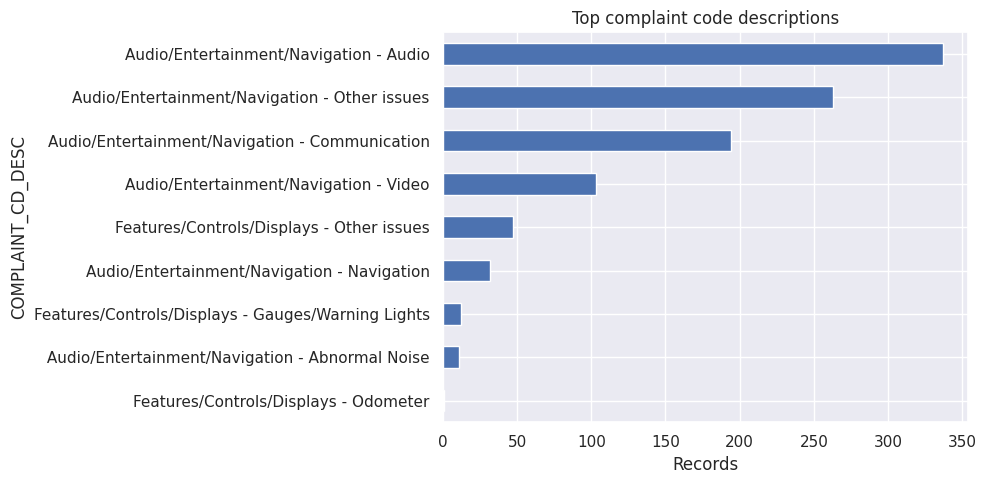

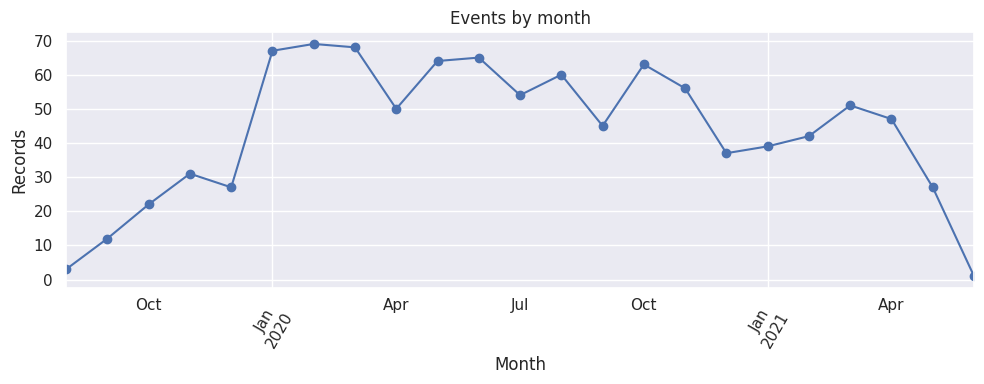

In [4]:
for col in ["CAUSAL_CD_DESC", "COMPLAINT_CD_DESC", "MAKE", "MODEL", "BUILD_PLANT_DESC"]:
    if col in df:
        print("\n", col)
        display(df[col].value_counts(dropna=False).head(15).rename_axis(col).reset_index(name="count"))

fig, ax = plt.subplots(figsize=(10, 5))
df["COMPLAINT_CD_DESC"].value_counts().head(12).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top complaint code descriptions"); ax.set_xlabel("Records"); plt.tight_layout(); plt.show()

if "Opened date_parsed" in df:
    monthly = df.groupby(df["Opened date_parsed"].dt.to_period("M")).size()
    ax = monthly.plot(figsize=(10,4), marker="o", title="Events by month")
    ax.set_xlabel("Month"); ax.set_ylabel("Records"); plt.xticks(rotation=60); plt.tight_layout(); plt.show()

## 4. Entity extraction and issue classification
Transparent keyword dictionaries extract candidate components/symptoms. These rules are a baseline; inspect false positives and extend dictionaries after reviewing examples.

,Event id,extracted_entities,issue_category
0,D-14801,"[radio/audio unit, display/screen, telematics/...",Other / Unspecified Infotainment
1,D-14869,"[radio/audio unit, display/screen, telematics/...",Other / Unspecified Infotainment
2,D-14555,"[radio/audio unit, display/screen, telematics/...",Other / Unspecified Infotainment
3,D-14704,"[radio/audio unit, diagnostic codes]",Controls / Display
4,D-15142,"[radio/audio unit, display/screen, software/pr...",Other / Unspecified Infotainment
5,D-15149,"[radio/audio unit, wiring/data bus, software/p...",Audio / Sound
6,D-14666,"[radio/audio unit, display/screen, wiring/data...",Other / Unspecified Infotainment
7,D-14857,"[radio/audio unit, display/screen, software/pr...",Display / Video
8,D-14465,"[radio/audio unit, telematics/connectivity, wi...",Controls / Display
9,D-14745,"[radio/audio unit, display/screen, wiring/data...",Other / Unspecified Infotainment


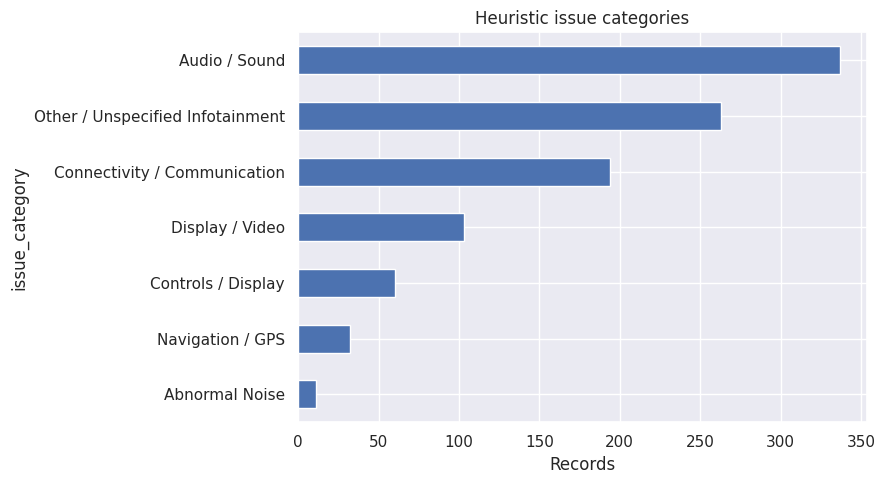

In [5]:
entity_patterns = {
    "radio/audio unit": [r"\bradio\b", r"\baudio\b", r"\bspeaker\b", r"\bsound\b", r"\bamplifier\b"],
    "display/screen": [r"\bdisplay\b", r"\bscreen\b", r"\bblack screen\b", r"\bblank screen\b"],
    "telematics/connectivity": [r"\bonstar\b", r"\btelematics\b", r"\bwifi\b", r"\bwi-fi\b", r"\bhotspot\b", r"\bethernet\b", r"\bbluetooth\b"],
    "wiring/data bus": [r"\bwiring\b", r"\bwire\b", r"\bconnector\b", r"\bground circuit\b", r"\bdata bus\b", r"\bserial data\b"],
    "software/programming": [r"\bsoftware\b", r"\bprogram(ming|med)?\b", r"\bfirmware\b", r"\bupdate(s|d)?\b", r"\bsps\b", r"\breset\b"],
    "controls/buttons": [r"\bcontrol buttons?\b", r"\bknobs?\b", r"\bbuttons?\b", r"\btouchscreen\b", r"\btouch screen\b"],
    "navigation/gps": [r"\bnavigation\b", r"\bgps\b", r"\bmaps?\b", r"\broute\b"],
    "diagnostic codes": [r"\bdtc\b", r"\bdiagnostic trouble code\b", r"\berror code\b", r"\bfault code\b"],
    "power/electrical": [r"\bpower\b", r"\bvoltage\b", r"\bbattery\b", r"\bshort(ed)?\b", r"\bfuse\b", r"\belectrical\b"]
}
compiled = {k: [re.compile(p) for p in pats] for k, pats in entity_patterns.items()}
def extract_entities(text):
    return [tag for tag, patterns in compiled.items() if any(p.search(text) for p in patterns)]
def classify_issue(row):
    # Prefer an explicit functional area in the supplied complaint code to reduce
    # bias from repeated words in long diagnostic narratives.
    complaint = str(row.get("COMPLAINT_CD_DESC", "")).lower().replace(" ", " ")
    complaint_detail = complaint.split("-")[-1].strip()
    if "communication" in complaint_detail: return "Connectivity / Communication"
    if complaint_detail == "audio": return "Audio / Sound"
    if "video" in complaint_detail: return "Display / Video"
    if "navigation" in complaint_detail: return "Navigation / GPS"
    if "features/controls/displays" in complaint: return "Controls / Display"
    if "other issues" in complaint_detail: return "Other / Unspecified Infotainment"
    if "abnormal noise" in complaint_detail: return "Abnormal Noise"
    if "odometer" in complaint_detail: return "Instrumentation / Odometer"
    if "gauges/warning lights" in complaint_detail: return "Gauges / Warning Lights"
    text = " ".join(str(row.get(c, "")) for c in ["combined_text", "CAUSAL_CD_DESC"]).lower()
    rules = [
        ("Connectivity / Communication", ["ethernet", "wifi", "wi-fi", "hotspot", "onstar", "telematics", "connect", "network", "data bus"]),
        ("Display / Video", ["black screen", "blank screen", "display", "screen", "camera", "video"]),
        ("Audio / Sound", ["audio", "sound", "speaker", "amplifier", "volume", "no sound"]),
        ("Software / Programming", ["software", "program", "firmware", "update", "reset", "reprogram"]),
        ("Electrical / Wiring", ["wiring", "wire", "circuit", "voltage", "battery", "ground", "shorted", "fuse", "power supply"]),
        ("Controls / Display", ["button", "knob", "control", "touchscreen", "unresponsive", "irresponsive"]),
        ("Navigation / GPS", ["gps", "map", "route"])
    ]
    for label, keywords in rules:
        if any(k in text for k in keywords): return label
    return "Other / Unclear"
df["extracted_entities"] = df["combined_text"].apply(extract_entities)
df["issue_category"] = df.apply(classify_issue, axis=1)
display(df[["Event id", "extracted_entities", "issue_category"]].head(10))
ax = df["issue_category"].value_counts().sort_values().plot(kind="barh", figsize=(9,5), title="Heuristic issue categories")
ax.set_xlabel("Records"); plt.tight_layout(); plt.show()

## 5. TF-IDF + K-Means clustering
Clustering is exploratory. Inspect the top terms and example records for each cluster before naming it. A cluster is not proof of a root cause.

,cluster,records,top_terms,example_event_ids
0,0,335,"screen, module, replaced, power, ok, tested, g...","D-14801, D-14869, D-14666, D-14465, D-14782"
1,1,264,"states, customer, customer states, xm, states ...","D-14673, D-14827, D-15256, D-14812, D-15118"
2,2,104,"camera, rear, coax, code, camera inop, cable, ...","D-14704, D-14520, D-15406, D-14507, D-14590"
3,3,47,"card, sd, sd card, error, navigation, error co...","D-15149, D-14615, D-14693, D-14721, D-14646"
4,4,56,"internal fault, fault, fault radio, internal, ...","D-15176, D-14796, D-15237, D-15216, D-14897"
5,5,194,"tac, case, tac case, customer, phone, usb, rep...","D-14555, D-15142, D-14857, D-14745, D-14850"


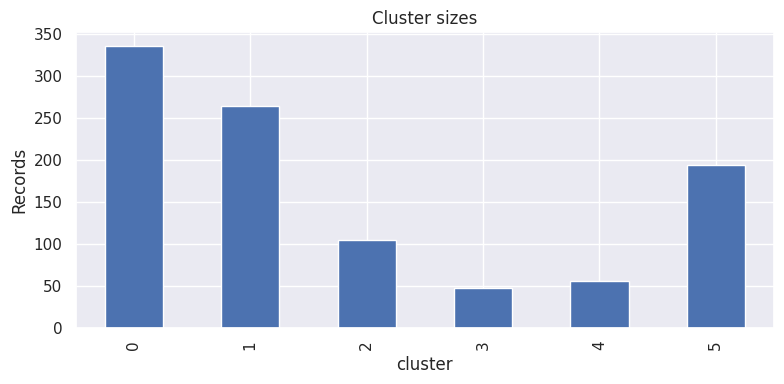

Sample silhouette score: 0.011


In [6]:
vectorizer = TfidfVectorizer(stop_words="english", max_features=1800, ngram_range=(1,2), min_df=3, max_df=0.9, sublinear_tf=True)
X = vectorizer.fit_transform(df["combined_text"].replace("", "missing text"))
k = 6  # baseline number of groups; compare alternatives if time permits
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["text_cluster"] = model.fit_predict(X)
terms = np.array(vectorizer.get_feature_names_out())
summary = []
for cluster_id in range(k):
    ids = np.where(df["text_cluster"].values == cluster_id)[0]
    top_terms = terms[model.cluster_centers_[cluster_id].argsort()[::-1][:10]].tolist()
    summary.append({"cluster": cluster_id, "records": len(ids), "top_terms": ", ".join(top_terms), "example_event_ids": ", ".join(df.iloc[ids]["Event id"].astype(str).head(5))})
cluster_summary = pd.DataFrame(summary)
display(cluster_summary)
cluster_summary.set_index("cluster")["records"].plot(kind="bar", title="Cluster sizes", figsize=(8,4)); plt.ylabel("Records"); plt.tight_layout(); plt.show()
# Optional diagnostic: silhouette can be expensive on large data; sample up to 500 rows.
if X.shape[0] > k and len(set(df["text_cluster"])) > 1:
    sample_n = min(500, X.shape[0])
    sample_idx = np.random.RandomState(42).choice(X.shape[0], sample_n, replace=False)
    try: print("Sample silhouette score:", round(silhouette_score(X[sample_idx], df["text_cluster"].iloc[sample_idx]), 3))
    except Exception as e: print("Silhouette diagnostic unavailable:", e)

### Clustering diagnostic and interpretation
The executed sample silhouette score is **0.011**. This value is close to zero and suggests that the six clusters are not clearly separated by this diagnostic. Keep the clusters as exploratory text-similarity groups only; do not describe them as validated issue classes or confirmed root causes. Review representative records and compare alternative cluster counts or text representations if stronger segmentation is needed.

### Issue-category method
The primary issue category is assigned using existing complaint-code descriptions when the rules match, with narrative keyword rules used as a fallback. As a result, the category distribution largely reorganizes existing structured complaint codes; it is not an independent, ground-truth text classifier. Validate labels against a manually reviewed sample before operational use.


## 6. Export the enriched dataset
The export retains original fields and adds parsed dates, entity tags, issue categories, and cluster IDs. Keep the raw file unchanged.

In [7]:
# ISO date fields make downstream use consistent.
for src, dst in [("Opened date_parsed", "opened_date_iso"), ("BUILD_DATE_parsed", "build_date_iso"), ("IN_USE_DATE_parsed", "in_use_date_iso")]:
    if src in df: df[dst] = df[src].dt.strftime("%Y-%m-%d")
# JSON strings make list-valued tags portable in CSV.
df["extracted_entities_json"] = df["extracted_entities"].apply(json.dumps)
remove = [c for c in df.columns if c.endswith("_clean") or c.endswith("_parsed")] + ["combined_text"]
export = df.drop(columns=[c for c in remove if c in df.columns])
export.to_csv("task2_processed_dataset.csv", index=False)
cluster_summary.to_csv("task2_cluster_summary.csv", index=False)
print("Saved task2_processed_dataset.csv and task2_cluster_summary.csv")

Saved task2_processed_dataset.csv and task2_cluster_summary.csv


## 7. Interpretation and limitations
- Use `COMPLAINT_CD_DESC` and `CAUSAL_CD_DESC` as existing structured reference fields, but verify their coding definitions with the data owner.
- Issue categories are a heuristic primary label: the function uses complaint-code descriptions where matched and keyword rules as a fallback. Therefore, these counts are not an independent, validated text-classification result.
- Entity tags are keyword matches and may miss synonyms or produce false positives. Audit a stratified sample manually before operational use.
- The six existing annotation fields (`Trigger`, `Failure Component`, `Failure Condition`, `Additional Context`, `Fix Component`, and `Fix Condition`) are sparse in the source and should not be treated as complete ground-truth labels.
- The six-cluster TF-IDF/K-Means result is exploratory. The sampled silhouette score is 0.011, which indicates weak separation under this diagnostic. Inspect example records and compare alternative approaches before using clusters operationally.
- The dataset has one unique `MODLYR` value, so model-year comparisons are not supported. Counts describe this supplied sample and do not establish fleet-wide failure rates, causal relationships, or predictive performance.

### Key validation note
Category totals should reconcile to 1,000 records. Keep the exported `task2_processed_dataset.csv` and `task2_cluster_summary.csv` together with this notebook. Confirm that the separate chart files exist in the submission folder; notebook-embedded plots alone do not guarantee the standalone PNG exports are present.
